<a href="https://colab.research.google.com/github/Amadi200/montra_hospitality/blob/main/07_bert_sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install required packages

In [1]:
!pip install -q transformers datasets accelerate scikit-learn pandas pyarrow matplotlib seaborn

Imports

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder

import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

pd.set_option("display.max_colwidth", 120)

Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load Data

In [4]:
DATA_PATH = "/content/drive/MyDrive/Montra_Hospitality/outputs/topic_sentiment/reviews_with_topic_sentiment.parquet"

df = pd.read_parquet(DATA_PATH)
print("Original shape:", df.shape)

# Select text + label
if "sentiment" in df.columns:
    label_col = "sentiment"
elif "sentiment_label" in df.columns:
    label_col = "sentiment_label"
else:
    raise ValueError("No sentiment column found.")

df_model = df[["review_text", label_col]].dropna().copy()
df_model = df_model[df_model["review_text"].str.strip() != ""]
df_model = df_model.rename(columns={label_col: "label"})

print("Modelling shape:", df_model.shape)
print("\nClass distribution:")
print(df_model["label"].value_counts())

Original shape: (34536, 31)
Modelling shape: (34536, 2)

Class distribution:
label
Positive    21491
Negative    10120
Neutral      2925
Name: count, dtype: int64


Prepare Data + Encode Labels + Split

In [5]:
# Select text + label
if "sentiment" in df.columns:
    label_col = "sentiment"
elif "sentiment_label" in df.columns:
    label_col = "sentiment_label"
else:
    raise ValueError("No sentiment column found. Available columns: " + str(df.columns.tolist()))

print(f"Using label column: '{label_col}'")

df_model = df[["review_text", label_col]].dropna().copy()
df_model = df_model[df_model["review_text"].str.strip() != ""]
df_model = df_model.rename(columns={label_col: "label"})

print("\nClass distribution:")
print(df_model["label"].value_counts())

# Encode labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_model["label_id"] = label_encoder.fit_transform(df_model["label"])

label2id = {label: int(idx) for idx, label in enumerate(label_encoder.classes_)}
id2label = {int(idx): label for label, idx in label2id.items()}

print("\nLabel mapping:")
print(label2id)

# Check that label_id exists
print("\nColumns in df_model:", df_model.columns.tolist())
print("label_id created successfully:", "label_id" in df_model.columns)

# Train / Validation Split
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df_model,
    test_size=0.15,
    random_state=42,
    stratify=df_model["label_id"]
)

print(f"\nTrain size: {len(train_df):,}")
print(f"Val size  : {len(val_df):,}")
print("Columns in train_df:", train_df.columns.tolist())

Using label column: 'sentiment'

Class distribution:
label
Positive    21491
Negative    10120
Neutral      2925
Name: count, dtype: int64

Label mapping:
{'Negative': 0, 'Neutral': 1, 'Positive': 2}

Columns in df_model: ['review_text', 'label', 'label_id']
label_id created successfully: True

Train size: 29,355
Val size  : 5,181
Columns in train_df: ['review_text', 'label', 'label_id']


Tokenization

In [6]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["review_text"],
        truncation=True,
        max_length=128,
        padding=False
    )

# Create Hugging Face datasets
train_dataset = Dataset.from_pandas(train_df[["review_text", "label_id"]].reset_index(drop=True))
val_dataset   = Dataset.from_pandas(val_df[["review_text", "label_id"]].reset_index(drop=True))

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset   = val_dataset.map(tokenize_function, batched=True)

# Rename for Trainer
train_dataset = train_dataset.rename_column("label_id", "labels")
val_dataset   = val_dataset.rename_column("label_id", "labels")

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

print("Tokenization completed successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/29355 [00:00<?, ? examples/s]

Map:   0%|          | 0/5181 [00:00<?, ? examples/s]

Tokenization completed successfully!


Load Model

In [7]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    id2label=id2label,
    label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training Arguments

In [8]:
output_dir = Path("/content/drive/MyDrive/Montra_Hospitality/outputs/bert_sentiment")
output_dir.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(output_dir / "checkpoints"),
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    report_to="none",
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
)

print("TrainingArguments created successfully!")

TrainingArguments created successfully!


Metrics function

In [9]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    f1_macro = f1_score(labels, predictions, average="macro")
    f1_weighted = f1_score(labels, predictions, average="weighted")

    return {
        "accuracy": accuracy,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted
    }

Trainer

In [10]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

print("Trainer created successfully!")

Trainer created successfully!


In [11]:
print("\nStarting BERT fine-tuning...")
trainer.train()


Starting BERT fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.116366,0.126705,0.955028,0.887088,0.953039
2,0.104548,0.095335,0.967381,0.921671,0.966294
3,0.087953,0.106064,0.967767,0.924212,0.967148


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5505, training_loss=0.12249637140497416, metrics={'train_runtime': 294.5315, 'train_samples_per_second': 299.0, 'train_steps_per_second': 18.691, 'total_flos': 1178348278258710.0, 'train_loss': 0.12249637140497416, 'epoch': 3.0})

Evaluate on Validation Set

In [12]:
print("\nEvaluating...")
predictions = trainer.predict(val_dataset)
preds = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids

print("\n" + "="*60)
print("BERT - CLASSIFICATION REPORT")
print("="*60)
print(classification_report(
    true_labels,
    preds,
    target_names=label_encoder.classes_,
    digits=4
))


Evaluating...



BERT - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.9784    0.9868    0.9826      1518
     Neutral     0.8458    0.7745    0.8086       439
    Positive     0.9778    0.9851    0.9815      3224

    accuracy                         0.9678      5181
   macro avg     0.9340    0.9155    0.9242      5181
weighted avg     0.9668    0.9678    0.9671      5181



Confusion Matrix

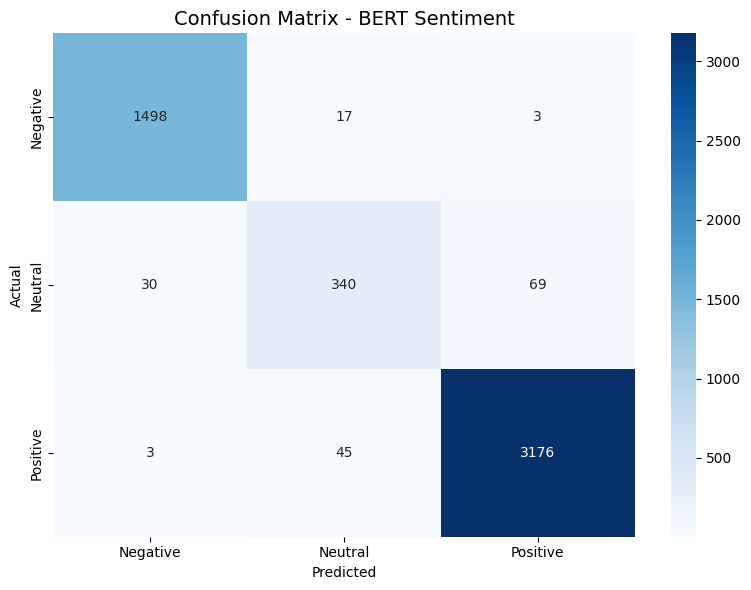

In [13]:
cm = confusion_matrix(true_labels, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Confusion Matrix - BERT Sentiment", fontsize=14)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Save Final Model

In [14]:
final_model_path = output_dir / "final_model"
trainer.save_model(str(final_model_path))
tokenizer.save_pretrained(str(final_model_path))

# Save label mapping
import json
with open(final_model_path / "label_mapping.json", "w") as f:
    json.dump({"label2id": label2id, "id2label": id2label}, f, indent=2)

print(f"\nModel saved to: {final_model_path}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: /content/drive/MyDrive/Montra_Hospitality/outputs/bert_sentiment/final_model
